# Loading Datasets

This tutorial starts with the regular AnnData path: load an AnnData object, choose the sample and label columns, and pass it to `ggml_ot.from_anndata`. At the end, we show shortcut wrappers for curated example datasets.

In [1]:
import ggml_ot
import scanpy as sc

## Loading from CELLxGENE

For public datasets hosted by CELLxGENE, `ggml_ot.data.load_cellxgene` downloads the AnnData object. After optional Scanpy preprocessing, pass the AnnData to `ggml_ot.from_anndata` and specify which `.obs` columns identify samples and labels.

In [2]:
dataset_id = "c1f6034b-7973-45e1-85e7-16933d0550bc.h5ad"
adata = ggml_ot.data.load_cellxgene(dataset_id)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

dataset = ggml_ot.from_anndata(
    adata,
    patient_col="sample",
    label_col="patient_group",
)
dataset.normalize()

print(dataset)
print(dataset.adata)

[ggml_ot] Neither `path=` nor `ggml_ot.settings.datadir` is set; caching dataset under /home/kuehn/ot_metric_learning/gaussian-ground-metric-learning/code/ggml-ot_privat/docs/source/tutorials/data. Set `ggml_ot.settings.datadir = ...` or pass `path=` to override.
AnnData object with n_obs × n_vars = 191795 × 2000
    obs: 'sample', 'n_counts', 'n_genes', 'percent_mito', 'doublet_score', 'dissociation_score', 'cell_type_original', 'patient_region_id', 'donor_id', 'patient_group', 'major_labl', 'final_cluster', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'featur

## Loading your own AnnData

ggml-ot does not rely on CELLxGENE. Any AnnData object works as long as it contains one observation column for samples/patients and one column for labels.

In [5]:
# As an example, we load the previously cached dataset
adata_path = f"data/{dataset_id}"
adata = sc.read_h5ad(adata_path)

dataset = ggml_ot.from_anndata(
    adata,
    patient_col="sample",
    label_col="patient_group",
)
dataset.normalize()

print(dataset)
print(dataset.adata)

AnnData object with n_obs × n_vars = 191795 × 28975
    obs: 'sample', 'n_counts', 'n_genes', 'percent_mito', 'doublet_score', 'dissociation_score', 'cell_type_original', 'patient_region_id', 'donor_id', 'patient_group', 'major_labl', 'final_cluster', 'assay_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'sex_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length'
    uns: 'X_approximate_distribution', 'batch_condition', 'cell_type_original_colors', 'citation', 'default_embedding', 'schema_reference', 'schema_version', 'title', 'ggml_params', 'ggml_dataset'
    obsm: 'X_har

## Curated dataset shortcuts

The shortcut functions wrap `load_cellxgene(...)` and `from_anndata(...)` for curated example datasets. They are useful for reproducing tutorials without repeating dataset IDs and known `.obs` column names.

In [6]:
dataset = ggml_ot.data.myocardial_infarction(n_top_genes=2000, normalize=True)

The shortcut still forwards dataset-construction options to `ggml_ot.from_anndata`. For example, you can pass `use_rep="X_pca"` to work with a representation stored in `adata.obsm["X_pca"]`, or `group_by="cell_type"` to use cell-type centroids.

In [9]:
dataset = ggml_ot.data.myocardial_infarction(
    normalize=True,
    n_top_genes=2000,
    # use_rep="X_pca",
    group_by="cell_type",
)

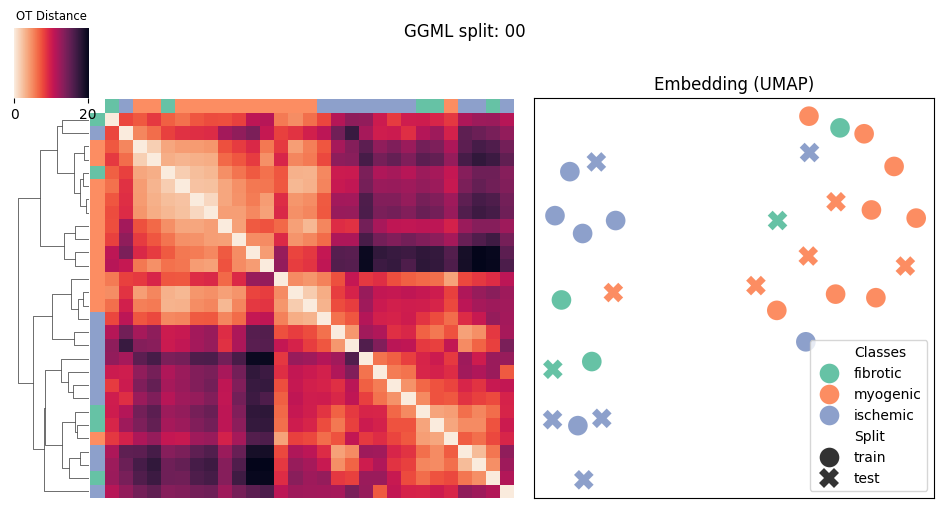

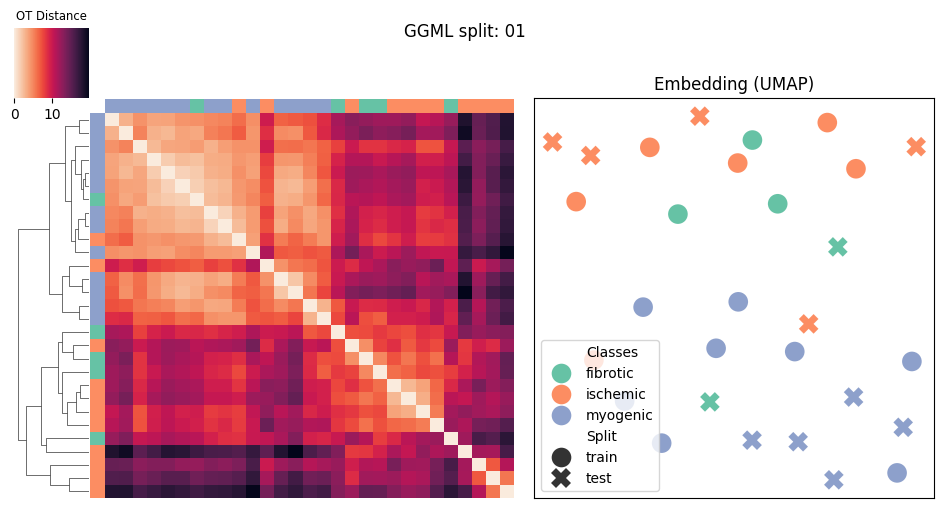

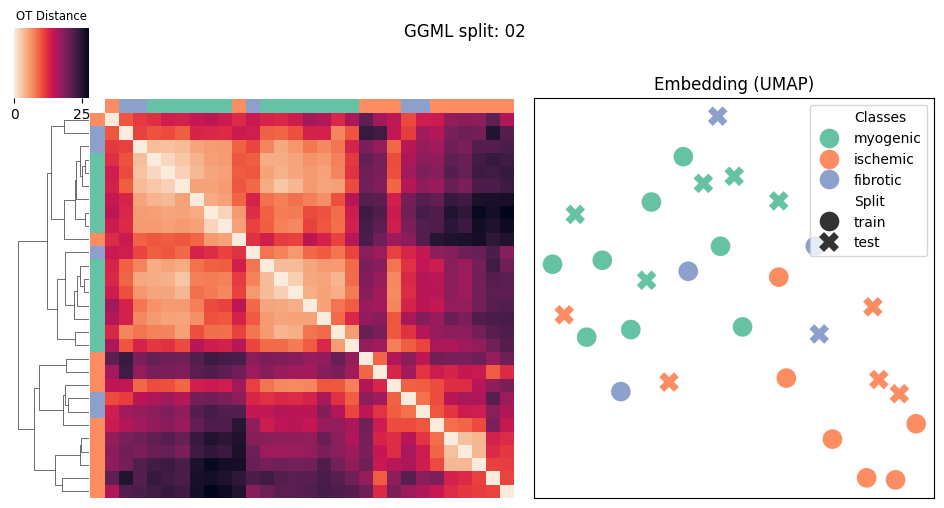

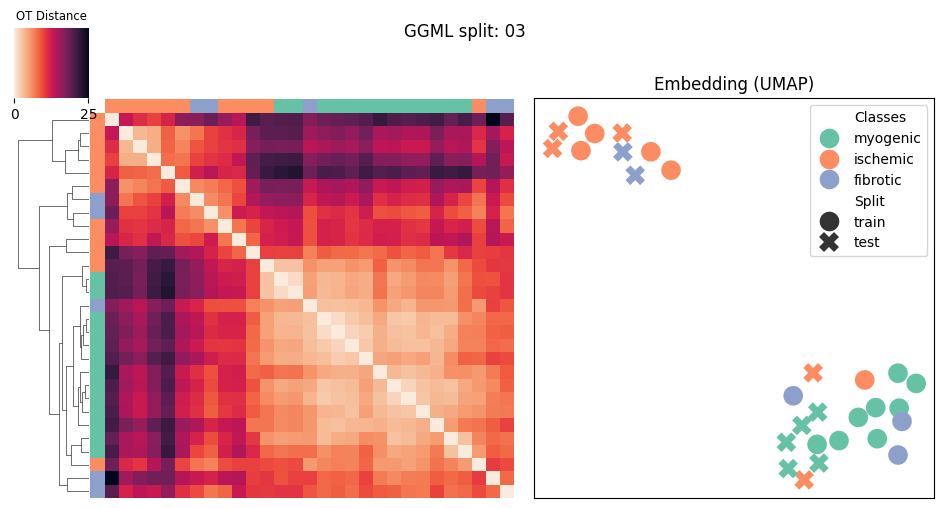

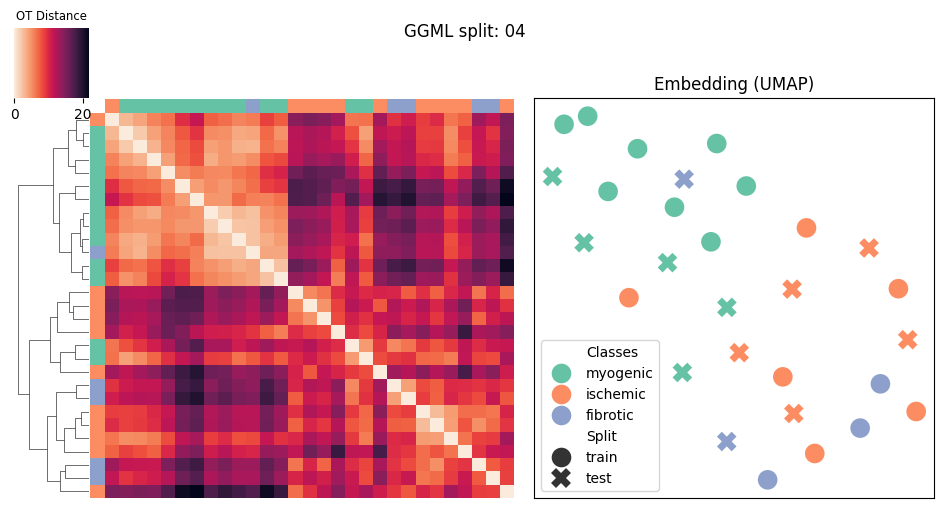

({'Ws': [array([[ 0.04157517,  0.01353727, -0.14645632, ..., -0.08268589,
           -0.02129376,  0.03837924],
          [-0.00369268, -0.00488895, -0.03868329, ...,  0.13724141,
            0.07912347, -0.02028023],
          [-0.00475935,  0.03765499,  0.06831949, ...,  0.00340076,
            0.00460171, -0.02246698],
          [-0.14249691, -0.08372505, -0.13138375, ..., -0.13592304,
           -0.15367614,  0.01199383],
          [ 0.14597979,  0.10676463,  0.11655395, ...,  0.10739662,
            0.03160247,  0.02270928]], shape=(5, 2000), dtype=float32),
   array([[ 0.02097465,  0.0201148 , -0.02448178, ..., -0.04440709,
           -0.02561833,  0.04851027],
          [-0.04029588,  0.01058042, -0.08056418, ...,  0.03198339,
            0.1318571 ,  0.31940687],
          [-0.04709679,  0.01076283, -0.03363878, ...,  0.02267516,
            0.06718951,  0.03499178],
          [ 0.02460276, -0.02094657,  0.0336997 , ..., -0.10331402,
           -0.07550231,  0.05149864],
      

In [10]:
dataset.train_test()